In [34]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the Parquet file
data = pd.read_parquet('yellow_tripdata_2024-01.parquet')

In [35]:
data.head()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee
0,2,2024-01-01 00:57:55,2024-01-01 01:17:43,1.0,1.72,1.0,N,186,79,2,17.7,1.0,0.5,0.00,0.0,1.0,22.70,2.5,0.0
1,1,2024-01-01 00:03:00,2024-01-01 00:09:36,1.0,1.80,1.0,N,140,236,1,10.0,3.5,0.5,3.75,0.0,1.0,18.75,2.5,0.0
2,1,2024-01-01 00:17:06,2024-01-01 00:35:01,1.0,4.70,1.0,N,236,79,1,23.3,3.5,0.5,3.00,0.0,1.0,31.30,2.5,0.0
3,1,2024-01-01 00:36:38,2024-01-01 00:44:56,1.0,1.40,1.0,N,79,211,1,10.0,3.5,0.5,2.00,0.0,1.0,17.00,2.5,0.0
4,1,2024-01-01 00:46:51,2024-01-01 00:52:57,1.0,0.80,1.0,N,211,148,1,7.9,3.5,0.5,3.20,0.0,1.0,16.10,2.5,0.0


In [38]:
duplicate_rows = data.duplicated() 

In [41]:
num_duplicates = duplicate_rows.sum()
num_duplicates

0

In [37]:
data[data['total_amount'] < 0 ].count()

VendorID                 35504
tpep_pickup_datetime     35504
tpep_dropoff_datetime    35504
passenger_count          35502
trip_distance            35504
RatecodeID               35502
store_and_fwd_flag       35502
PULocationID             35504
DOLocationID             35504
payment_type             35504
fare_amount              35504
extra                    35504
mta_tax                  35504
tip_amount               35504
tolls_amount             35504
improvement_surcharge    35504
total_amount             35504
congestion_surcharge     35502
Airport_fee              35502
dtype: int64

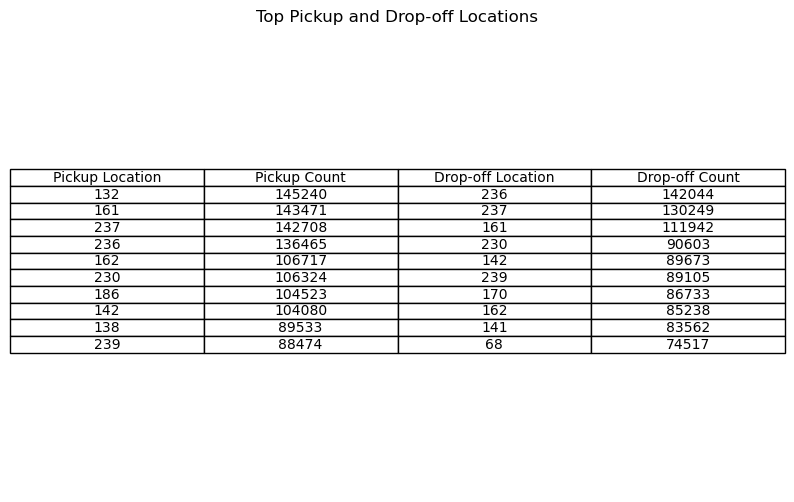

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the Parquet file
data = pd.read_parquet('yellow_tripdata_2024-01.parquet')

# Count occurrences of pickup and drop-off locations
pickup_counts = data['PULocationID'].value_counts().head(10)
dropoff_counts = data['DOLocationID'].value_counts().head(10)

# Combine counts into a single DataFrame
top_locations = pd.DataFrame({
    'Pickup Location': pickup_counts.index,
    'Pickup Count': pickup_counts.values,
    'Drop-off Location': dropoff_counts.index,
    'Drop-off Count': dropoff_counts.values
})

# Display the table
plt.figure(figsize=(10, 6))
plt.axis('tight')
plt.axis('off')
table = plt.table(cellText=top_locations.values,
                  colLabels=top_locations.columns,
                  cellLoc='center',
                  loc='center')
plt.title('Top Pickup and Drop-off Locations')
plt.show()


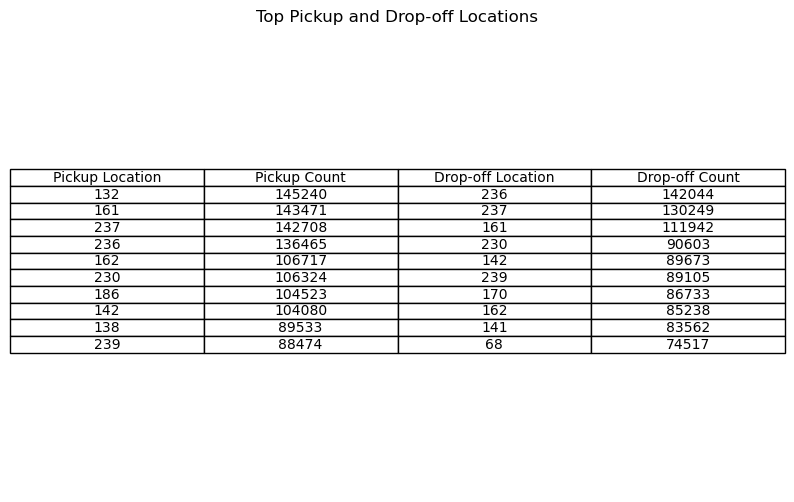

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the Parquet file
data = pd.read_parquet('yellow_tripdata_2024-01.parquet')

# Count occurrences of pickup and drop-off locations
pickup_counts = data['PULocationID'].value_counts().head(10)
dropoff_counts = data['DOLocationID'].value_counts().head(10)

# Combine counts into a single DataFrame
top_locations = pd.DataFrame({
    'Pickup Location': pickup_counts.index,
    'Pickup Count': pickup_counts.values,
    'Drop-off Location': dropoff_counts.index,
    'Drop-off Count': dropoff_counts.values
})

# Display the table
plt.figure(figsize=(10, 6))
plt.axis('tight')
plt.axis('off')
table = plt.table(cellText=top_locations.values,
                  colLabels=top_locations.columns,
                  cellLoc='center',
                  loc='center')
plt.title('Top Pickup and Drop-off Locations')
plt.show()


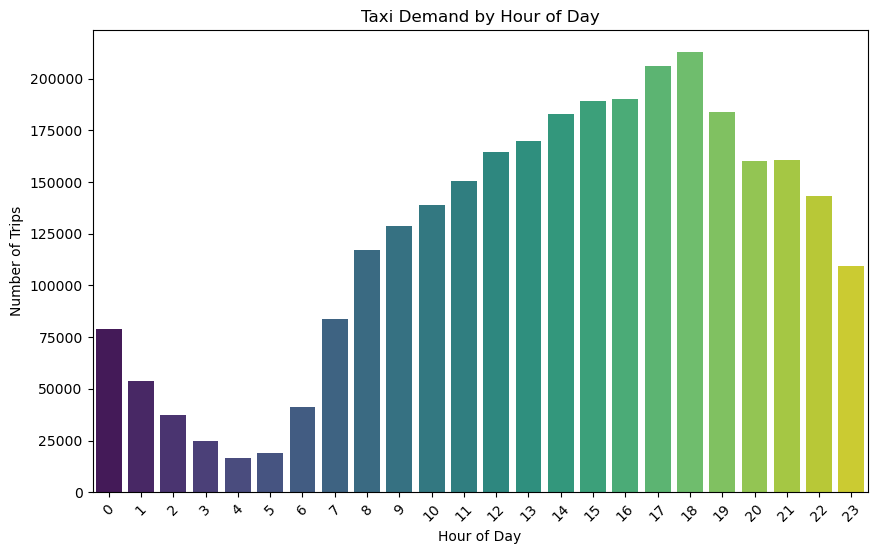

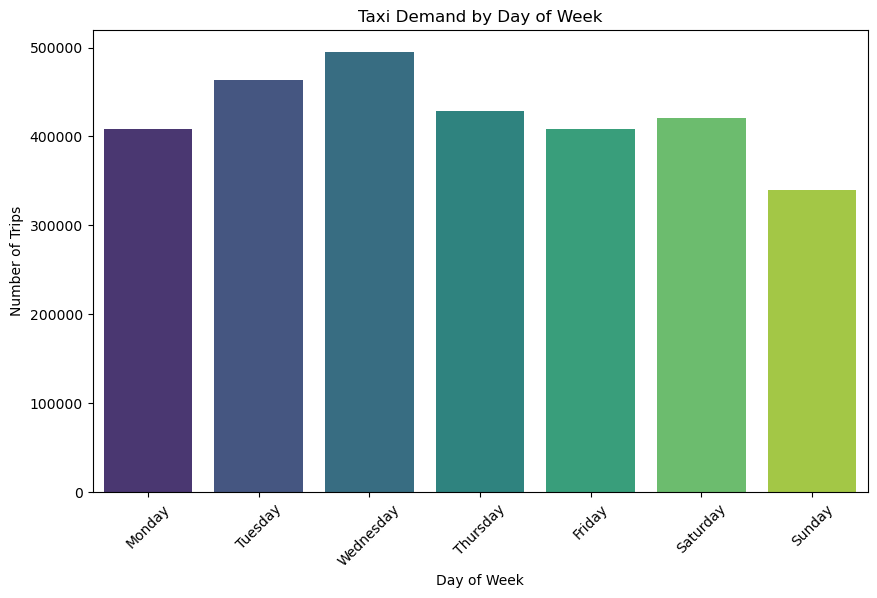

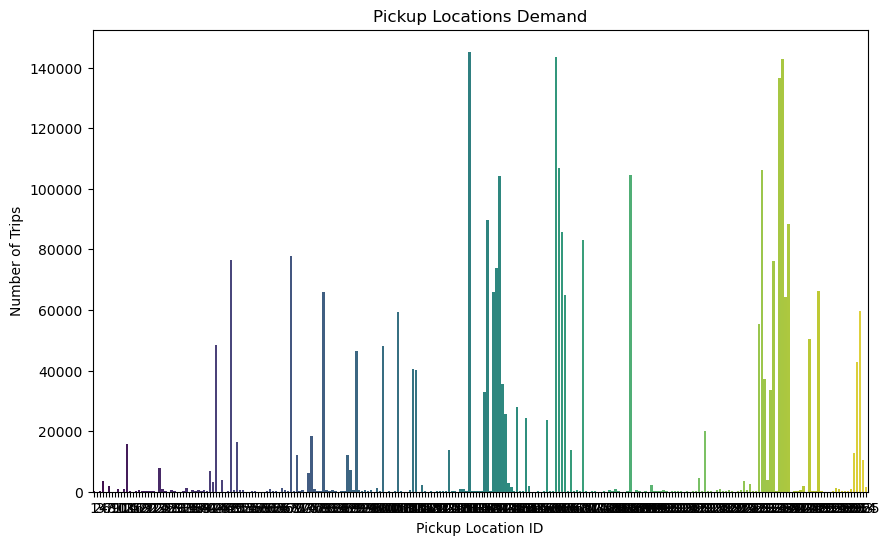

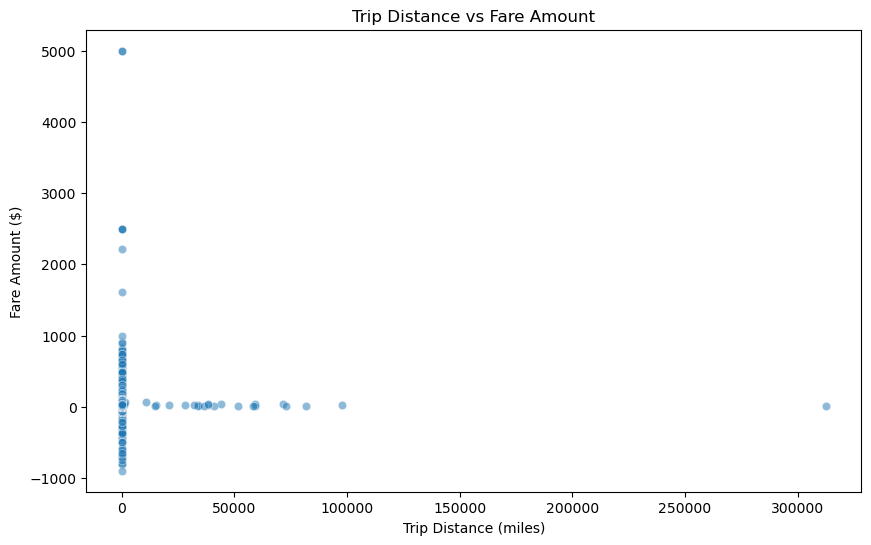

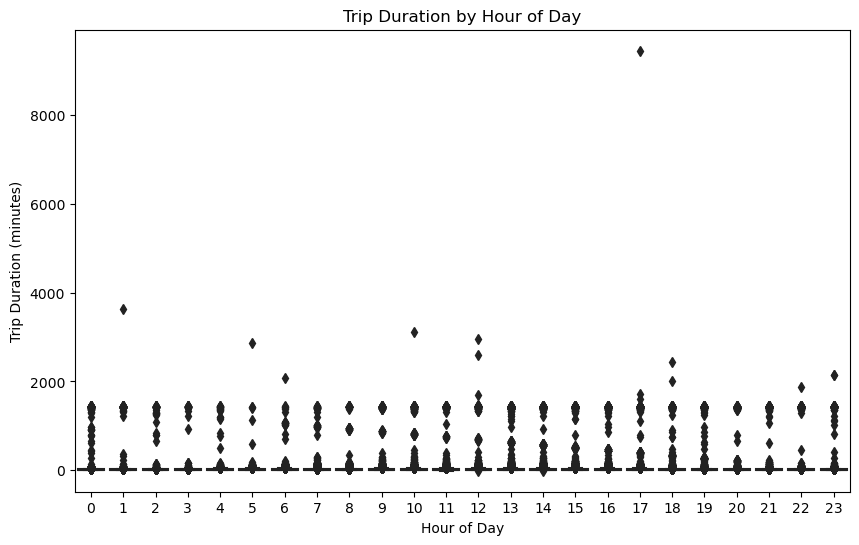

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the Parquet file
data = pd.read_parquet('yellow_tripdata_2024-01.parquet')

# Convert datetime columns
data['tpep_pickup_datetime'] = pd.to_datetime(data['tpep_pickup_datetime'])
data['tpep_dropoff_datetime'] = pd.to_datetime(data['tpep_dropoff_datetime'])

# Extract hour and day of week for analysis
data['pickup_hour'] = data['tpep_pickup_datetime'].dt.hour
data['pickup_day'] = data['tpep_pickup_datetime'].dt.day_name()

# 1. Demand Analysis: Peak hours and days
plt.figure(figsize=(10, 6))
sns.countplot(data=data, x='pickup_hour', palette='viridis')
plt.title('Taxi Demand by Hour of Day')
plt.xlabel('Hour of Day')
plt.ylabel('Number of Trips')
plt.xticks(rotation=45)
plt.show()

plt.figure(figsize=(10, 6))
sns.countplot(data=data, x='pickup_day', order=['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'], palette='viridis')
plt.title('Taxi Demand by Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Number of Trips')
plt.xticks(rotation=45)
plt.show()

# 2. Geospatial Demand Patterns: Heatmap of pickup locations
plt.figure(figsize=(10, 6))
pickup_counts = data['PULocationID'].value_counts()
sns.barplot(x=pickup_counts.index, y=pickup_counts.values, palette='viridis')
plt.title('Pickup Locations Demand')
plt.xlabel('Pickup Location ID')
plt.ylabel('Number of Trips')
plt.show()

# 3. Fare Distribution and Revenue Analysis
plt.figure(figsize=(10, 6))
sns.scatterplot(data=data, x='trip_distance', y='fare_amount', alpha=0.5)
plt.title('Trip Distance vs Fare Amount')
plt.xlabel('Trip Distance (miles)')
plt.ylabel('Fare Amount ($)')
plt.show()

# 4. Impact of Traffic Conditions: Travel time analysis
data['trip_duration'] = (data['tpep_dropoff_datetime'] - data['tpep_pickup_datetime']).dt.total_seconds() / 60  # in minutes
plt.figure(figsize=(10, 6))
sns.boxplot(data=data, x='pickup_hour', y='trip_duration', palette='viridis')
plt.title('Trip Duration by Hour of Day')
plt.xlabel('Hour of Day')
plt.ylabel('Trip Duration (minutes)')
plt.show()


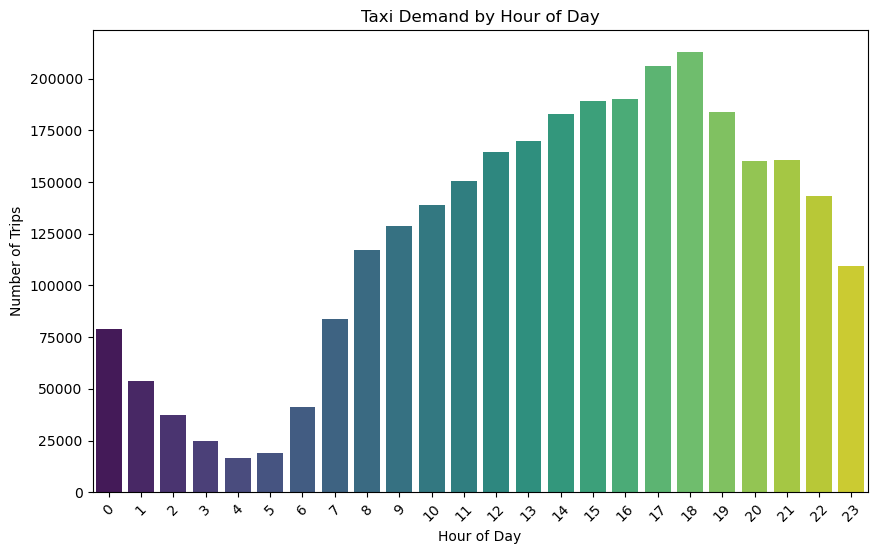

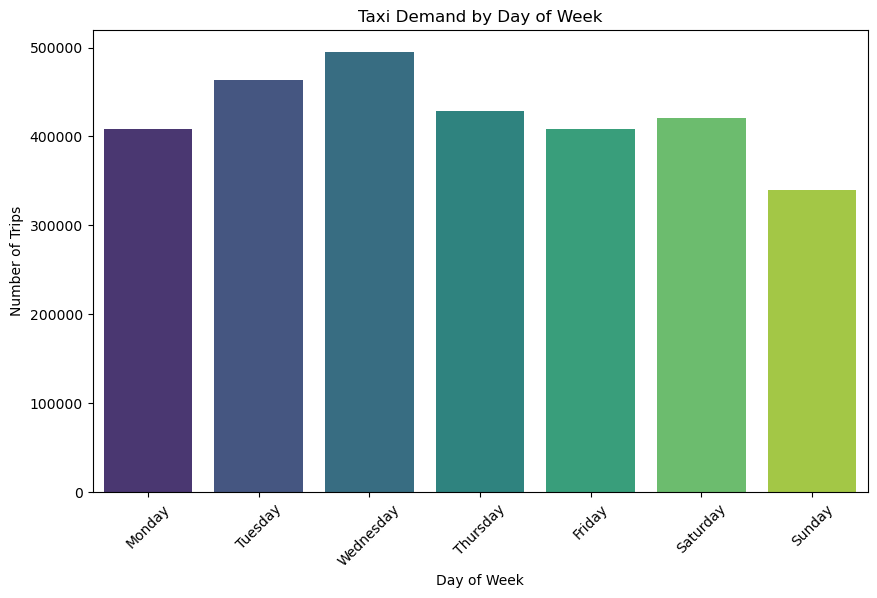

In [4]:

# 1. Demand Analysis: Peak hours and days
plt.figure(figsize=(10, 6))
sns.countplot(data=data, x='pickup_hour', palette='viridis')
plt.title('Taxi Demand by Hour of Day')
plt.xlabel('Hour of Day')
plt.ylabel('Number of Trips')
plt.xticks(rotation=45)
plt.show()

plt.figure(figsize=(10, 6))
sns.countplot(data=data, x='pickup_day', order=['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'], palette='viridis')
plt.title('Taxi Demand by Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Number of Trips')
plt.xticks(rotation=45)
plt.show()

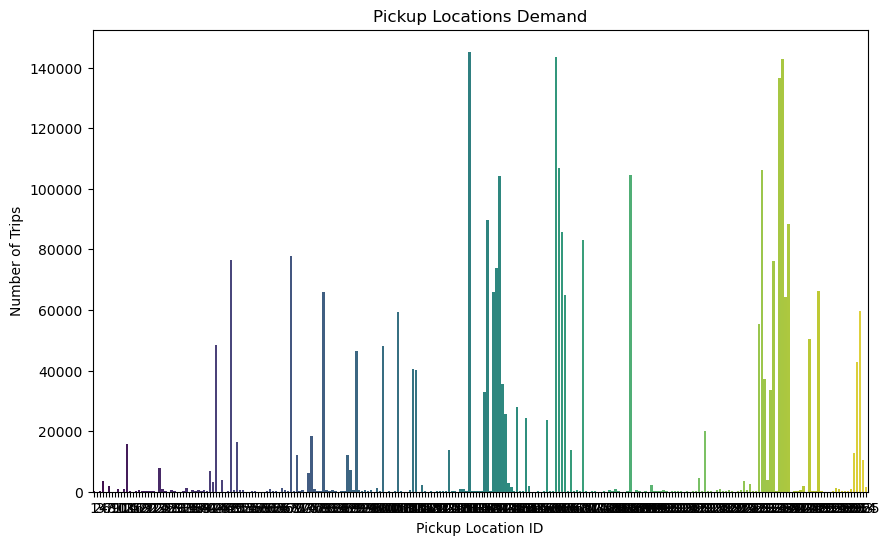

In [5]:
# 2. Geospatial Demand Patterns: Heatmap of pickup locations
plt.figure(figsize=(10, 6))
pickup_counts = data['PULocationID'].value_counts()
sns.barplot(x=pickup_counts.index, y=pickup_counts.values, palette='viridis')
plt.title('Pickup Locations Demand')
plt.xlabel('Pickup Location ID')
plt.ylabel('Number of Trips')
plt.show()

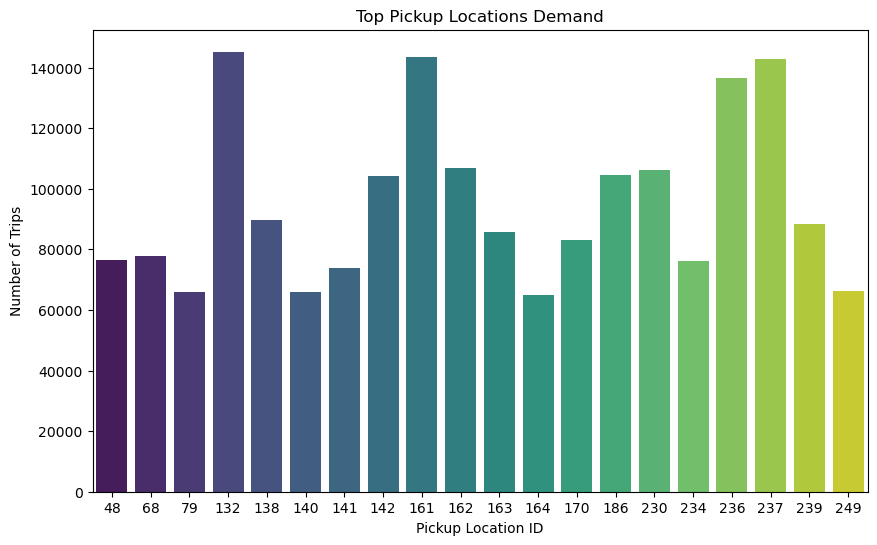

In [11]:
plt.figure(figsize=(10, 6))
pickup_counts = data['PULocationID'].value_counts().head(20)  # Limit to top 20 locations for clarity
sns.barplot(y=pickup_counts.values, x=pickup_counts.index, palette='viridis')
plt.title('Top Pickup Locations Demand')
plt.xlabel('Pickup Location ID')
plt.ylabel('Number of Trips')
plt.show()


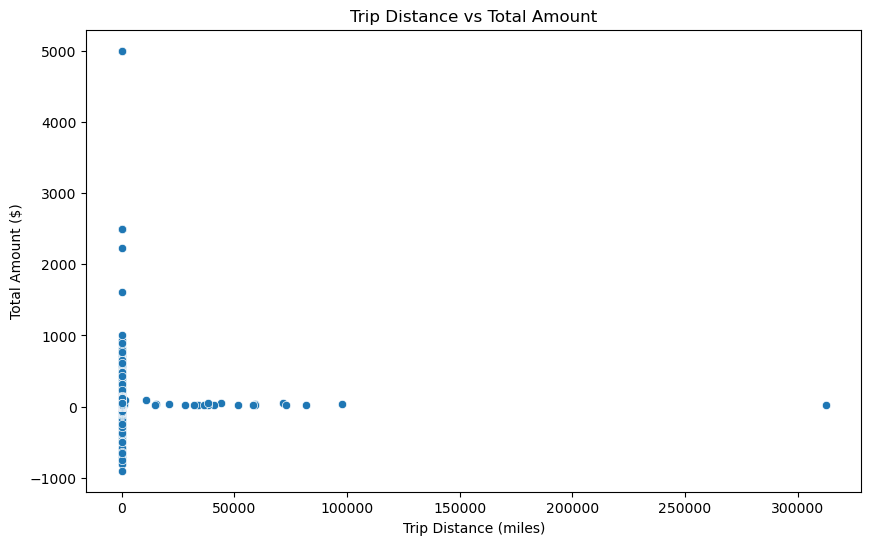

In [23]:
# 3. Fare Distribution and Revenue Analysis
plt.figure(figsize=(10, 6))
sns.scatterplot(data=data, x='trip_distance', y='total_amount')
plt.title('Trip Distance vs Total Amount')
plt.xlabel('Trip Distance (miles)')
plt.ylabel('Total Amount ($)')
plt.show()

In [29]:
data[data['total_amount'] < 0].count()

VendorID                 35504
tpep_pickup_datetime     35504
tpep_dropoff_datetime    35504
passenger_count          35502
trip_distance            35504
RatecodeID               35502
store_and_fwd_flag       35502
PULocationID             35504
DOLocationID             35504
payment_type             35504
fare_amount              35504
extra                    35504
mta_tax                  35504
tip_amount               35504
tolls_amount             35504
improvement_surcharge    35504
total_amount             35504
congestion_surcharge     35502
Airport_fee              35502
trip_duration_minutes    35504
dtype: int64

In [24]:
data

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,trip_duration_minutes
0,2,2024-01-01 00:57:55,2024-01-01 01:17:43,1.0,1.72,1.0,N,186,79,2,17.70,1.00,0.5,0.00,0.00,1.0,22.70,2.5,0.0,19.800000
1,1,2024-01-01 00:03:00,2024-01-01 00:09:36,1.0,1.80,1.0,N,140,236,1,10.00,3.50,0.5,3.75,0.00,1.0,18.75,2.5,0.0,6.600000
2,1,2024-01-01 00:17:06,2024-01-01 00:35:01,1.0,4.70,1.0,N,236,79,1,23.30,3.50,0.5,3.00,0.00,1.0,31.30,2.5,0.0,17.916667
3,1,2024-01-01 00:36:38,2024-01-01 00:44:56,1.0,1.40,1.0,N,79,211,1,10.00,3.50,0.5,2.00,0.00,1.0,17.00,2.5,0.0,8.300000
4,1,2024-01-01 00:46:51,2024-01-01 00:52:57,1.0,0.80,1.0,N,211,148,1,7.90,3.50,0.5,3.20,0.00,1.0,16.10,2.5,0.0,6.100000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2964619,2,2024-01-31 23:45:59,2024-01-31 23:54:36,NaN,3.18,NaN,None,107,263,0,15.77,0.00,0.5,2.00,0.00,1.0,21.77,NaN,NaN,8.616667
2964620,1,2024-01-31 23:13:07,2024-01-31 23:27:52,NaN,4.00,NaN,None,114,236,0,18.40,1.00,0.5,2.34,0.00,1.0,25.74,NaN,NaN,14.750000
2964621,2,2024-01-31 23:19:00,2024-01-31 23:38:00,NaN,3.33,NaN,None,211,25,0,19.97,0.00,0.5,0.00,0.00,1.0,23.97,NaN,NaN,19.000000
2964622,2,2024-01-31 23:07:23,2024-01-31 23:25:14,NaN,3.06,NaN,None,107,13,0,23.88,0.00,0.5,5.58,0.00,1.0,33.46,NaN,NaN,17.850000


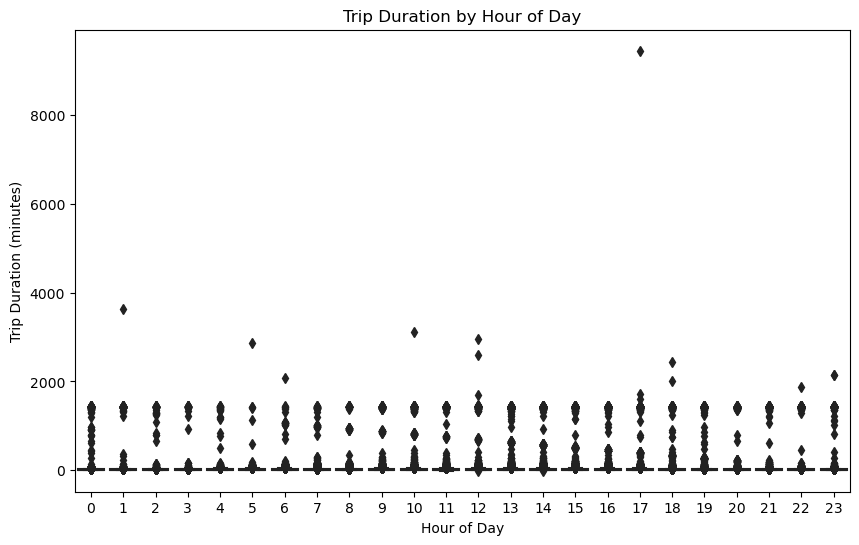

In [13]:
# 4. Impact of Traffic Conditions: Travel time analysis
data['trip_duration'] = (data['tpep_dropoff_datetime'] - data['tpep_pickup_datetime']).dt.total_seconds() / 60  # in minutes
plt.figure(figsize=(10, 6))
sns.boxplot(data=data, x='pickup_hour', y='trip_duration', palette='viridis')
plt.title('Trip Duration by Hour of Day')
plt.xlabel('Hour of Day')
plt.ylabel('Trip Duration (minutes)')
plt.show()

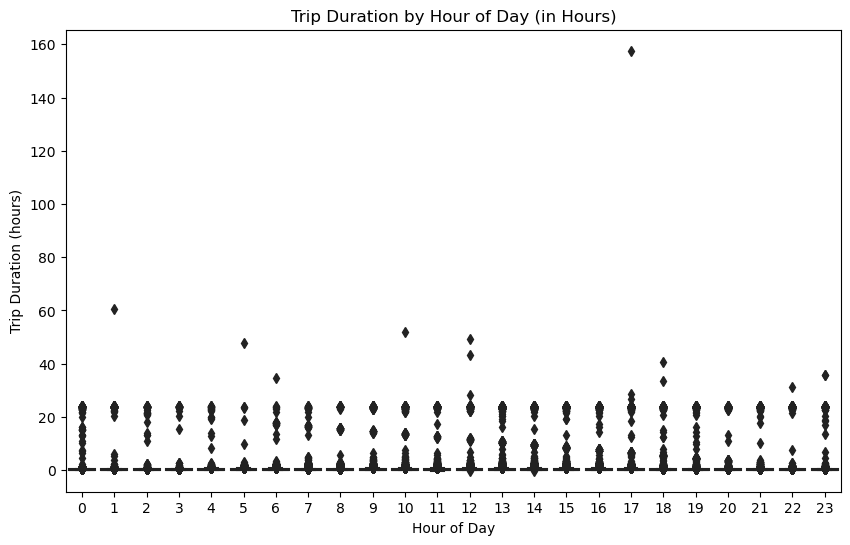

In [14]:
# Calculate trip duration in hours
data['trip_duration_hours'] = (data['tpep_dropoff_datetime'] - data['tpep_pickup_datetime']).dt.total_seconds() / 3600  # in hours

# Plotting the box plot for trip duration in hours
plt.figure(figsize=(10, 6))
sns.boxplot(data=data, x='pickup_hour', y='trip_duration_hours', palette='viridis')
plt.title('Trip Duration by Hour of Day (in Hours)')
plt.xlabel('Hour of Day')
plt.ylabel('Trip Duration (hours)')
plt.show()


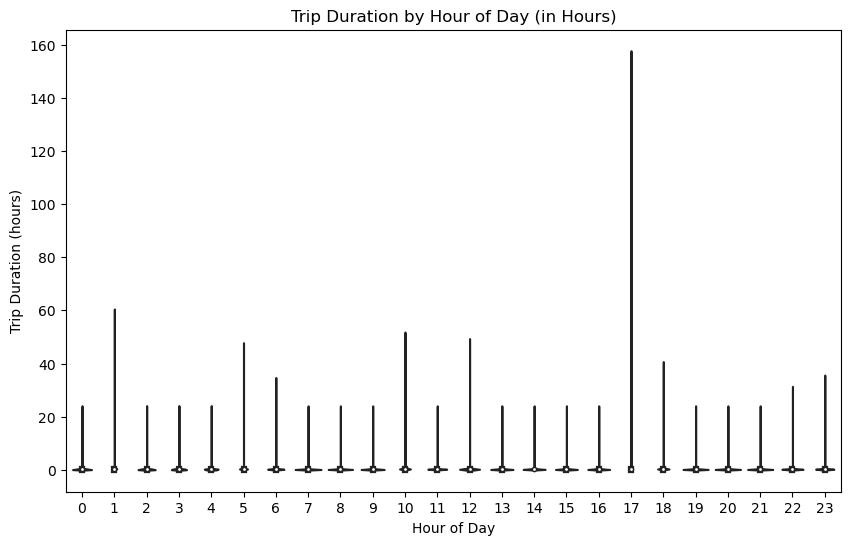

In [15]:
# Violin plot for trip duration in hours
plt.figure(figsize=(10, 6))
sns.violinplot(data=data, x='pickup_hour', y='trip_duration_hours', palette='viridis')
plt.title('Trip Duration by Hour of Day (in Hours)')
plt.xlabel('Hour of Day')
plt.ylabel('Trip Duration (hours)')
plt.show()


C:\Users\User\AppData\Local\Temp\ipykernel_2092\834386681.py:6: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.lineplot(data=avg_trip_duration, x='pickup_hour', y='trip_duration_hours', marker='o', palette='viridis')
C:\Users\User\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\User\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


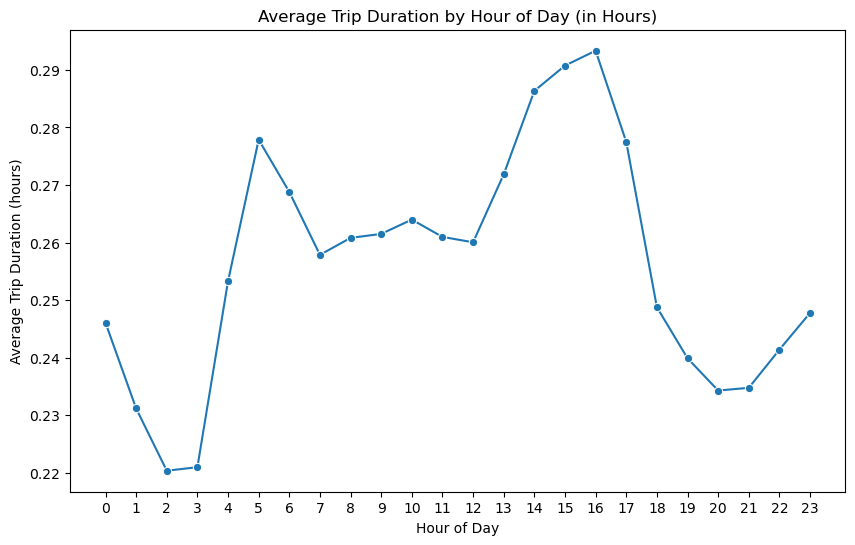

In [16]:
# Calculate average trip duration per hour
avg_trip_duration = data.groupby('pickup_hour')['trip_duration_hours'].mean().reset_index()

# Line plot for average trip duration in hours
plt.figure(figsize=(10, 6))
sns.lineplot(data=avg_trip_duration, x='pickup_hour', y='trip_duration_hours', marker='o', palette='viridis')
plt.title('Average Trip Duration by Hour of Day (in Hours)')
plt.xlabel('Hour of Day')
plt.ylabel('Average Trip Duration (hours)')
plt.xticks(range(0, 24))  # Show all hours
plt.show()


In [18]:
# Calculate average trip duration per hour in minutes
avg_trip_duration_minutes = data.groupby('pickup_hour')['trip_duration_minutes'].mean().reset_index()

# Line plot for average trip duration in minutes
plt.figure(figsize=(10, 6))
sns.lineplot(data=avg_trip_duration_minutes, x='pickup_hour', y='trip_duration_minutes', marker='o', palette='viridis')
plt.title('Average Trip Duration by Hour of Day (in Minutes)')
plt.xlabel('Hour of Day')
plt.ylabel('Average Trip Duration (minutes)')
plt.xticks(range(0, 24))  # Show all hours
plt.show()


KeyError: 'Column not found: trip_duration_minutes'

In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the Parquet file
data = pd.read_parquet('yellow_tripdata_2024-01.parquet')

# Ensure datetime columns are in the correct format
data['tpep_pickup_datetime'] = pd.to_datetime(data['tpep_pickup_datetime'])
data['tpep_dropoff_datetime'] = pd.to_datetime(data['tpep_dropoff_datetime'])

# Calculate trip duration in minutes
data['trip_duration_minutes'] = (data['tpep_dropoff_datetime'] - data['tpep_pickup_datetime']).dt.total_seconds() / 60  # in minutes

# Violin plot for trip duration in minutes
plt.figure(figsize=(10, 6))
sns.violinplot(data=data, x='pickup_hour', y='trip_duration_minutes', palette='viridis')
plt.title('Trip Duration by Hour of Day (in Minutes)')
plt.xlabel('Hour of Day')
plt.ylabel('Trip Duration (minutes)')
plt.show()

# Calculate average trip duration per hour in minutes
avg_trip_duration_minutes = data.groupby('pickup_hour')['trip_duration_minutes'].mean().reset_index()

# Line plot for average trip duration in minutes
plt.figure(figsize=(10, 6))
sns.lineplot(data=avg_trip_duration_minutes, x='pickup_hour', y='trip_duration_minutes', marker='o', palette='viridis')
plt.title('Average Trip Duration by Hour of Day (in Minutes)')
plt.xlabel('Hour of Day')
plt.ylabel('Average Trip Duration (minutes)')
plt.xticks(range(0, 24))  # Show all hours
plt.show()


ValueError: Could not interpret input 'pickup_hour'

<Figure size 1000x600 with 0 Axes>

In [31]:
# 5. Correlation Heatmap between numerical features

plt.figure(figsize=(10, 6))
corr = data[['trip_distance', 'fare_amount', 'total_amount', 'trip_duration', 'passenger_count']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', linewidths=0.5)
plt.title("Correlation Heatmap of Key Features")
plt.show()

KeyError: "['trip_duration'] not in index"

<Figure size 1000x600 with 0 Axes>

In [32]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the Parquet file
data = pd.read_parquet('yellow_tripdata_2024-01.parquet')

# Select relevant columns
correlation_data = data[['trip_distance', 'fare_amount', 'total_amount', 'trip_duration_minutes', 'passenger_count']]

# Calculate the correlation matrix
correlation_matrix = correlation_data.corr()

# Set up the matplotlib figure
plt.figure(figsize=(10, 6))

# Draw the heatmap
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap='coolwarm', square=True, cbar_kws={"shrink": .8})

# Add titles and labels
plt.title('Correlation Heatmap')
plt.xticks(rotation=45)
plt.yticks(rotation=45)
plt.show()


KeyError: "['trip_duration_minutes'] not in index"

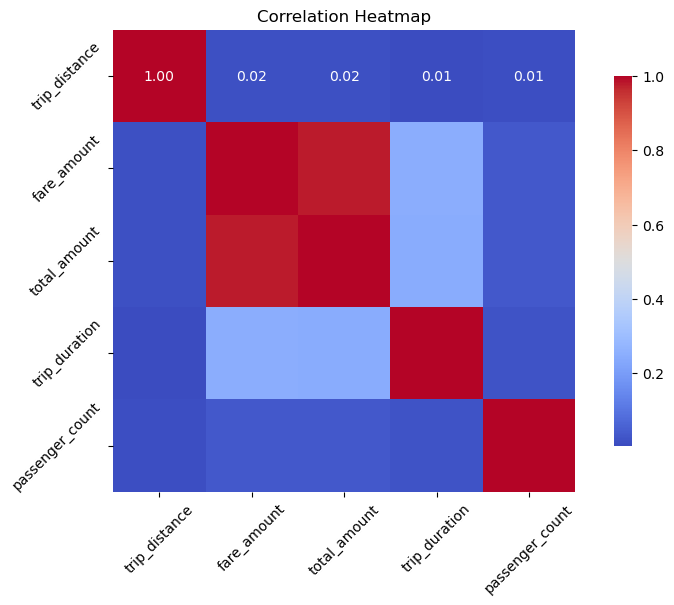

In [33]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the Parquet file
data = pd.read_parquet('yellow_tripdata_2024-01.parquet')

# Calculate trip duration in minutes
data['trip_duration'] = (data['tpep_dropoff_datetime'] - data['tpep_pickup_datetime']).dt.total_seconds() / 60  # in minutes

# Select relevant columns
correlation_data = data[['trip_distance', 'fare_amount', 'total_amount', 'trip_duration', 'passenger_count']]

# Calculate the correlation matrix
correlation_matrix = correlation_data.corr()

# Set up the matplotlib figure
plt.figure(figsize=(10, 6))

# Draw the heatmap
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap='coolwarm', square=True, cbar_kws={"shrink": .8})

# Add titles and labels
plt.title('Correlation Heatmap')
plt.xticks(rotation=45)
plt.yticks(rotation=45)
plt.show()
